In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

In [16]:
train = pd.read_csv(r"C:\Users\HP\Downloads\train_ctrUa4K.csv")

test = pd.read_csv(r"C:\Users\HP\Downloads\test_lAUu6dG.csv")

train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [17]:
train.shape

(614, 13)

In [18]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [19]:
train.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [20]:
train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

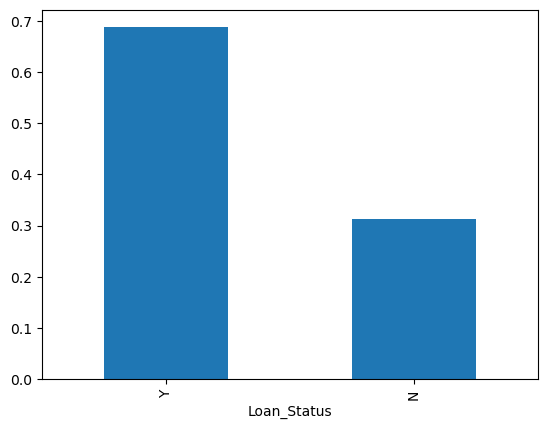

In [21]:
train['Loan_Status'].value_counts(normalize=True).plot.bar()
plt.show()

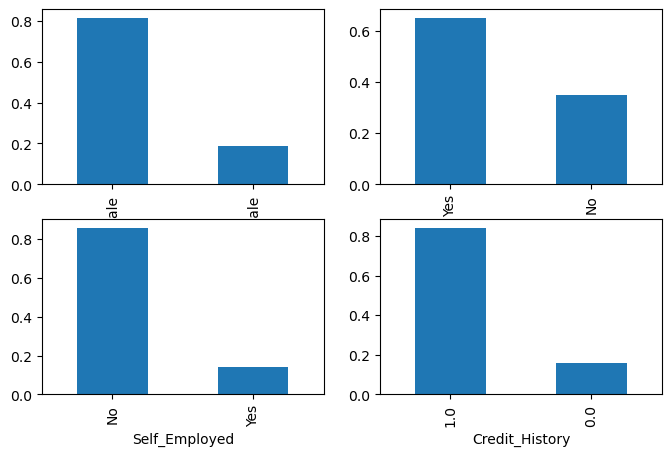

In [22]:
plt.figure(figsize=(8,5))
plt.subplot(221)
train['Gender'].value_counts(normalize=True).plot.bar()
plt.subplot(222)
train['Married'].value_counts(normalize=True).plot.bar()
plt.subplot(223)
train['Self_Employed'].value_counts(normalize=True).plot.bar()
plt.subplot(224)
train['Credit_History'].value_counts(normalize=True).plot.bar()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_5656\3629513168.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train['ApplicantIncome'])


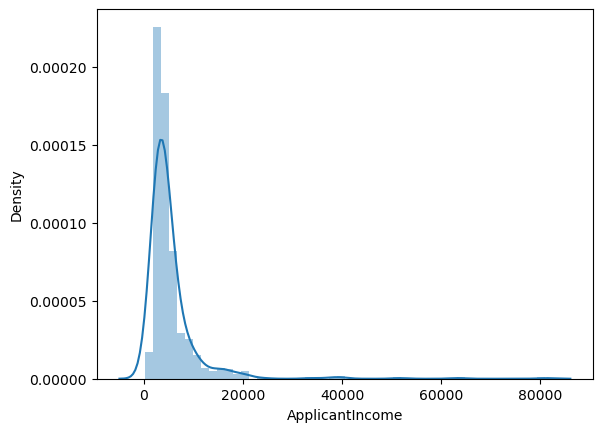

In [23]:
sns.distplot(train['ApplicantIncome'])
plt.show()

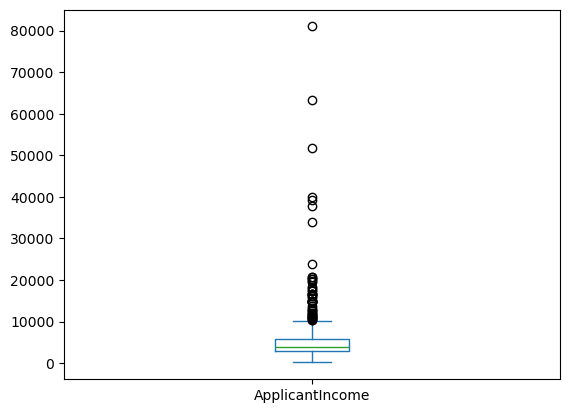

In [24]:
train['ApplicantIncome'].plot.box()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_5656\3704579626.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train['LoanAmount'])


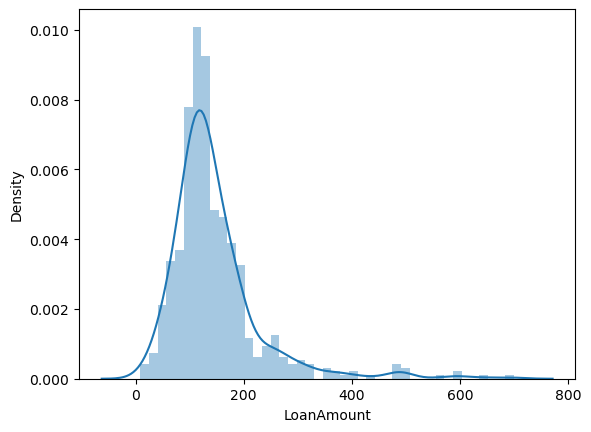

In [25]:
sns.distplot(train['LoanAmount'])
plt.show()

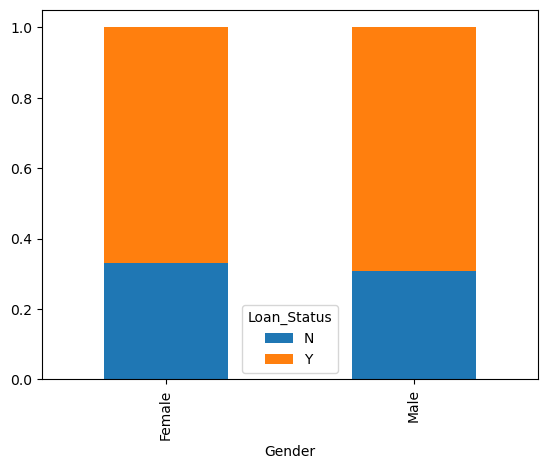

In [26]:
Gender = pd.crosstab(train['Gender'],train['Loan_Status'])

Gender.div(Gender.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True)

plt.show()

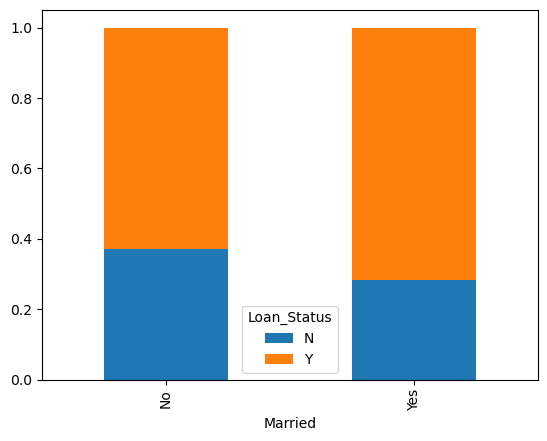

In [27]:
Married = pd.crosstab(train['Married'],train['Loan_Status'])
Married.div(Married.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True)
plt.show()

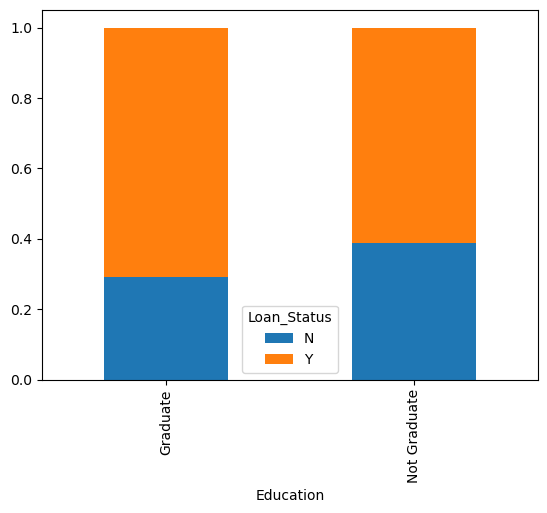

In [28]:
Education = pd.crosstab(train['Education'],train['Loan_Status'])
Education.div(Education.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True)
plt.show()

In [29]:
train['Gender'].fillna(train['Gender'].mode()[0],inplace=True)
train['Married'].fillna(train['Married'].mode()[0],inplace=True)
train['Dependents'].fillna(train['Dependents'].mode()[0],inplace=True)
train['Self_Employed'].fillna(train['Self_Employed'].mode()[0],inplace=True)

train['LoanAmount'].fillna(train['LoanAmount'].median(),inplace=True)

train['Loan_Amount_Term'].fillna(
train['Loan_Amount_Term'].mode()[0],inplace=True)

train['Credit_History'].fillna(
train['Credit_History'].mode()[0],inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_5656\3350260027.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train['Gender'].fillna(train['Gender'].mode()[0],inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_5656\3350260027.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

F

In [30]:
test['Gender'].fillna(test['Gender'].mode()[0],inplace=True)
test['Married'].fillna(test['Married'].mode()[0],inplace=True)
test['Dependents'].fillna(test['Dependents'].mode()[0],inplace=True)
test['Self_Employed'].fillna(test['Self_Employed'].mode()[0],inplace=True)
test['LoanAmount'].fillna(test['LoanAmount'].median(),inplace=True)
test['Loan_Amount_Term'].fillna(
test['Loan_Amount_Term'].mode()[0],inplace=True)
test['Credit_History'].fillna(
test['Credit_History'].mode()[0],inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_5656\700603007.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test['Gender'].fillna(test['Gender'].mode()[0],inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_5656\700603007.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For e

In [31]:
train.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

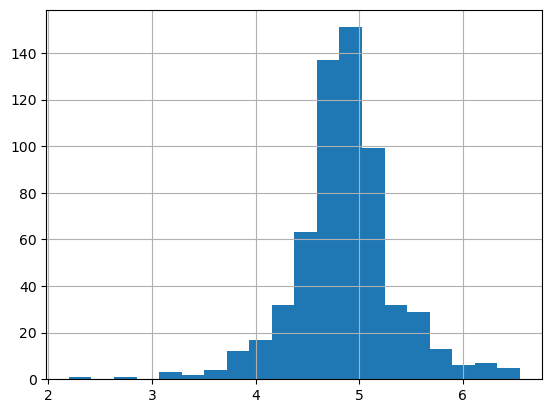

In [32]:
train['LoanAmount_log'] = np.log(train['LoanAmount'])
train['LoanAmount_log'].hist(bins=20)
plt.show()

In [33]:
train["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

In [34]:
train['Loan_Status'] = train['Loan_Status'].map(
{'Y':1,'N':0})

In [35]:
train['Total_Income'] = train['ApplicantIncome'] + train['CoapplicantIncome']
test['Total_Income'] = test['ApplicantIncome'] + test['CoapplicantIncome']

In [36]:
train['Total_Income_log'] = np.log(train['Total_Income'])
test['Total_Income_log'] = np.log(test['Total_Income'])

In [37]:
train['EMI'] = train['LoanAmount'] / train['Loan_Amount_Term']
test['EMI'] = test['LoanAmount'] / test['Loan_Amount_Term']

In [38]:
train['Balance Income'] = train['Total_Income'] - (train['EMI']*1000)
test['Balance Income'] = test['Total_Income'] - (test['EMI']*1000)

In [39]:
train = pd.get_dummies(train)
test = pd.get_dummies(test)

In [40]:
X = train.drop('Loan_Status',axis=1)
y = train['Loan_Status']

In [41]:
 train.shape

(614, 640)

In [42]:
X.shape

(614, 639)

In [43]:
train.isnull().sum()

ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                 0
Loan_Amount_Term           0
Credit_History             0
                          ..
Self_Employed_No           0
Self_Employed_Yes          0
Property_Area_Rural        0
Property_Area_Semiurban    0
Property_Area_Urban        0
Length: 640, dtype: int64

In [44]:
i = 1
kf = StratifiedKFold(n_splits=5, random_state=1, shuffle=True)

score = []

for train_index, test_index in kf.split(X, y):

    xtr,xvl = X.iloc[train_index],X.iloc[test_index]
 

    ytr,yvl = y.iloc[train_index],y.iloc[test_index]
    

    model = LogisticRegression(max_iter=10000,solver = "liblinear")

    model.fit(xtr, ytr)

    pred_test = model.predict(xvl)

    sc = accuracy_score(yvl, pred_test)

    score.append(sc)

    print("Fold", i, "Accuracy:", sc)

    i += 1

print("Mean Accuracy:", sum(score)/len(score))

Fold 1 Accuracy: 0.7886178861788617
Fold 2 Accuracy: 0.8373983739837398
Fold 3 Accuracy: 0.7967479674796748
Fold 4 Accuracy: 0.8211382113821138
Fold 5 Accuracy: 0.7868852459016393
Mean Accuracy: 0.806157536985206


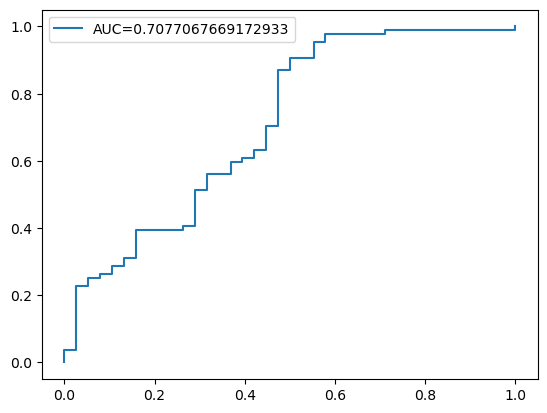

In [45]:
pred_prob = model.predict_proba(xvl)[:,1]

fpr,tpr,_ = roc_curve(yvl,pred_prob)

auc = roc_auc_score(yvl,pred_prob)

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend()

plt.show()

In [46]:
rf = RandomForestClassifier(
random_state=1,
max_depth=3,
n_estimators=41)

rf.fit(X,y)

pred_rf = rf.predict(X)

accuracy_score(y,pred_rf)

0.6889250814332247

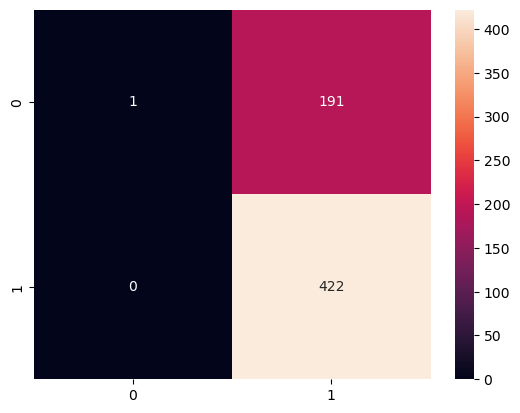

In [47]:
cm = confusion_matrix(y,pred_rf)

sns.heatmap(
cm,
annot=True,
fmt='d')

plt.show()

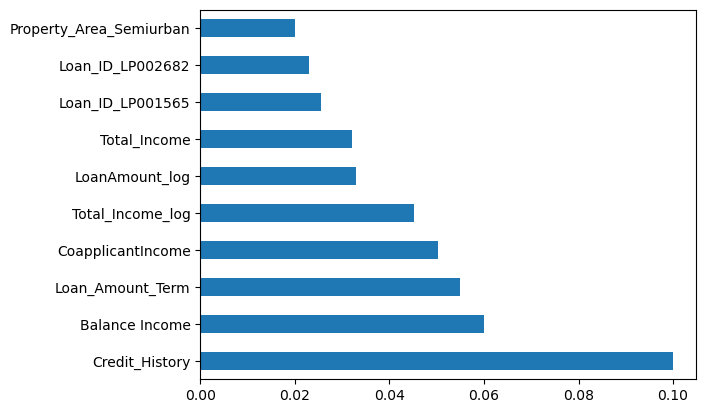

In [48]:
importance = pd.Series(
rf.feature_importances_,
index=X.columns)

importance.nlargest(10).plot(
kind='barh')

plt.show()

In [49]:
tree = DecisionTreeClassifier()

tree.fit(X,y)

pred_tree = tree.predict(X)

accuracy_score(y,pred_tree)

1.0

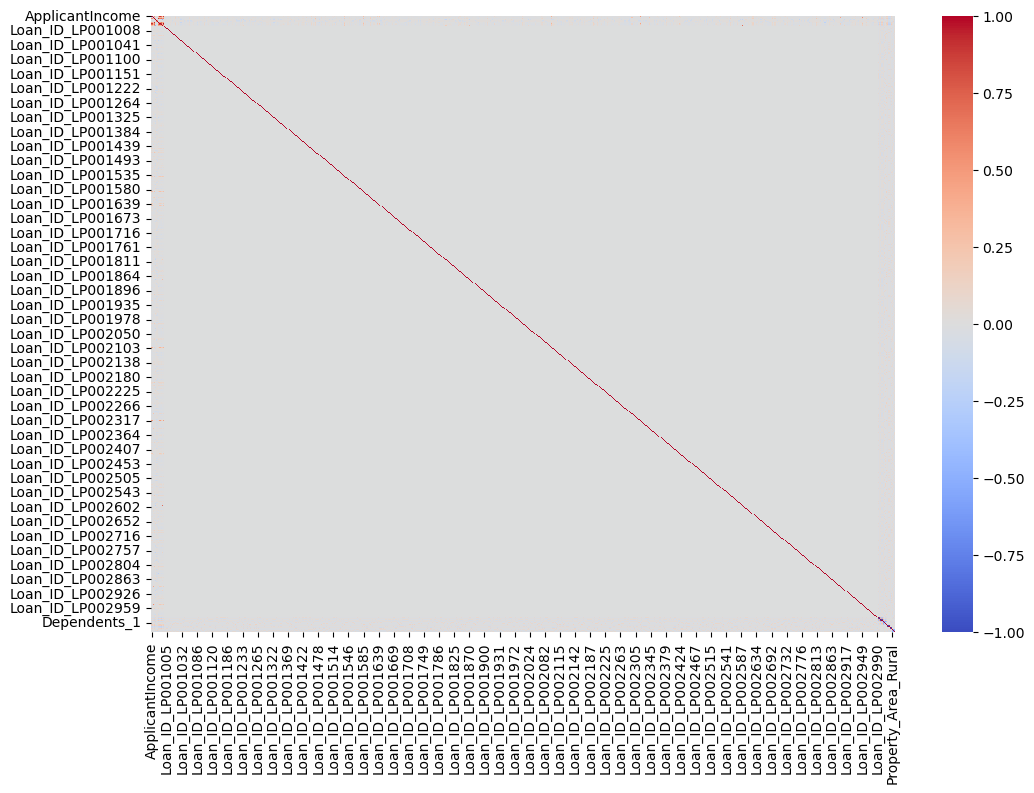

In [50]:
plt.figure(figsize=(12,8))
sns.heatmap(train.corr(numeric_only=True), cmap = "coolwarm")
plt.show()

In [51]:
print(train.isnull().sum())

ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                 0
Loan_Amount_Term           0
Credit_History             0
                          ..
Self_Employed_No           0
Self_Employed_Yes          0
Property_Area_Rural        0
Property_Area_Semiurban    0
Property_Area_Urban        0
Length: 640, dtype: int64


In [52]:
results = pd.DataFrame({
    'Model':['Logistic Regression','Decision Tree','Random Forest','XGBoost'],
    'Score':[0.7847,0.63,0.7638,0.7361]
})

print(results)

                 Model   Score
0  Logistic Regression  0.7847
1        Decision Tree  0.6300
2        Random Forest  0.7638
3              XGBoost  0.7361


In [53]:
print(
classification_report(
y,
pred_rf))

              precision    recall  f1-score   support

           0       1.00      0.01      0.01       192
           1       0.69      1.00      0.82       422

    accuracy                           0.69       614
   macro avg       0.84      0.50      0.41       614
weighted avg       0.79      0.69      0.56       614



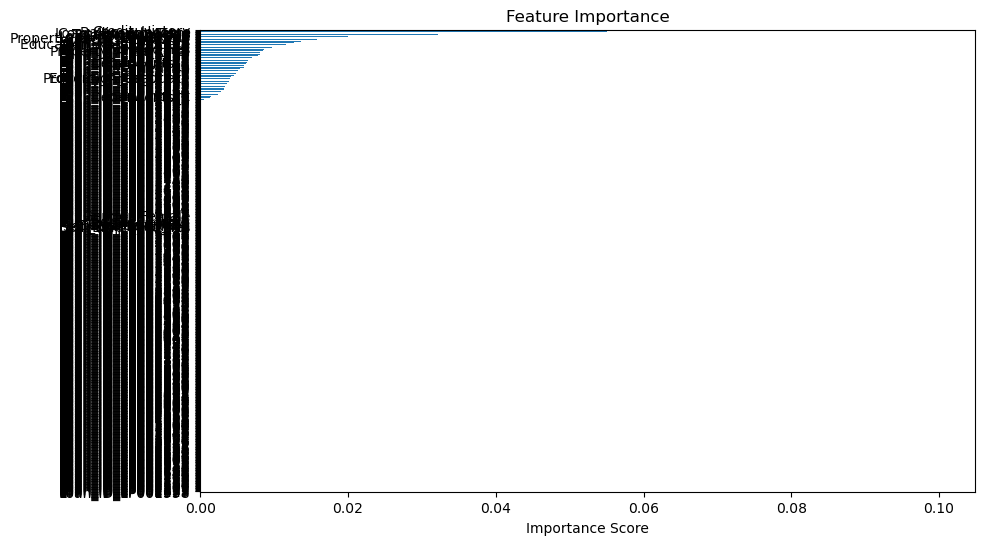

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importance.sort_values(ascending=True).plot(
    kind='barh',
    figsize=(10,6)
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.show()

In [55]:
importance = pd.Series(rf.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
print(importance.head(10))

Credit_History             0.099929
Balance Income             0.060038
Loan_Amount_Term           0.055016
CoapplicantIncome          0.050295
Total_Income_log           0.045178
LoanAmount_log             0.032977
Total_Income               0.032143
Loan_ID_LP001565           0.025570
Loan_ID_LP002682           0.023047
Property_Area_Semiurban    0.019963
dtype: float64


In [56]:
import pickle

pickle.dump(
rf,
open(
"loan_prediction_model.pkl",
"wb"))

In [57]:
test.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Total_Income,Total_Income_log,EMI,Balance Income,Loan_ID_LP001015,...,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,5720,0,110.0,360.0,1.0,5720,8.651724,0.305556,5414.444444,True,...,False,False,False,True,False,True,False,False,False,True
1,3076,1500,126.0,360.0,1.0,4576,8.428581,0.350000,4226.000000,False,...,True,False,False,True,False,True,False,False,False,True
2,5000,1800,208.0,360.0,1.0,6800,8.824678,0.577778,6222.222222,False,...,False,True,False,True,False,True,False,False,False,True
3,2340,2546,100.0,360.0,1.0,4886,8.494129,0.277778,4608.222222,False,...,False,True,False,True,False,True,False,False,False,True
4,3276,0,78.0,360.0,1.0,3276,8.094378,0.216667,3059.333333,False,...,False,False,False,False,True,True,False,False,False,True


In [58]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=1)

rf.fit(X, y)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [59]:
print(X.shape)
print(test.shape)

(614, 639)
(367, 391)


In [60]:
print(X.columns.difference(test.columns))

Index(['LoanAmount_log', 'Loan_ID_LP001002', 'Loan_ID_LP001003',
       'Loan_ID_LP001005', 'Loan_ID_LP001006', 'Loan_ID_LP001008',
       'Loan_ID_LP001011', 'Loan_ID_LP001013', 'Loan_ID_LP001014',
       'Loan_ID_LP001018',
       ...
       'Loan_ID_LP002959', 'Loan_ID_LP002960', 'Loan_ID_LP002961',
       'Loan_ID_LP002964', 'Loan_ID_LP002974', 'Loan_ID_LP002978',
       'Loan_ID_LP002979', 'Loan_ID_LP002983', 'Loan_ID_LP002984',
       'Loan_ID_LP002990'],
      dtype='object', length=615)


In [61]:
print(test.columns.difference(X.columns))

Index(['Loan_ID_LP001015', 'Loan_ID_LP001022', 'Loan_ID_LP001031',
       'Loan_ID_LP001035', 'Loan_ID_LP001051', 'Loan_ID_LP001054',
       'Loan_ID_LP001055', 'Loan_ID_LP001056', 'Loan_ID_LP001059',
       'Loan_ID_LP001067',
       ...
       'Loan_ID_LP002952', 'Loan_ID_LP002954', 'Loan_ID_LP002962',
       'Loan_ID_LP002965', 'Loan_ID_LP002969', 'Loan_ID_LP002971',
       'Loan_ID_LP002975', 'Loan_ID_LP002980', 'Loan_ID_LP002986',
       'Loan_ID_LP002989'],
      dtype='object', length=367)


In [62]:
test = test.reindex(columns=X.columns, fill_value=0)

In [63]:
test_pred = rf.predict(test)

In [65]:
submission = pd.read_csv(
    r"C:\Users\HP\Downloads\sample_submission_49d68Cx.csv"
)

In [66]:
submission['Loan_Status'] = test_pred

In [67]:
submission['Loan_Status'] = submission['Loan_Status'].map({1:'Y',0:'N'})

In [68]:
submission.head()

,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,Y


In [69]:
submission.to_csv("submission.csv", index=False)

In [70]:
print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

Training dataset: (614, 640)
Testing dataset: (367, 639)


In [71]:
print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

Training dataset: (614, 640)
Testing dataset: (367, 639)


In [72]:
print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

Training Shape: (614, 640)
Testing Shape: (367, 639)
